# SVM — MNIST: 3 ou 6

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import fetch_openml
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

In [2]:
mnist = fetch_openml("mnist_784", version=1)
rotulos = mnist.target.astype(int).to_numpy()
indices = np.flatnonzero(np.isin(rotulos[:60000], [3, 6]))
indices_treino, _ = train_test_split(
    indices, train_size=300, stratify=rotulos[indices], random_state=42
)
indices_teste = np.flatnonzero(np.isin(rotulos[60000:], [3, 6])) + 60000

X_treino = mnist.data.iloc[indices_treino].to_numpy(dtype=float) / 255
X_teste = mnist.data.iloc[indices_teste].to_numpy(dtype=float) / 255
y_treino = rotulos[indices_treino]
y_teste = rotulos[indices_teste]

In [3]:
def mostrar_digitos(previsoes=None):
    indices = np.concatenate([np.flatnonzero(y_teste == digito)[:6] for digito in [3, 6]])
    fig, eixos = plt.subplots(2, 6, figsize=(10, 4))
    for eixo, indice in zip(eixos.flat, indices):
        eixo.imshow(X_teste[indice].reshape(28, 28), cmap="gray_r")
        titulo = f"Real: {y_teste[indice]}"
        if previsoes is not None:
            titulo += f" | SVM: {previsoes[indice]}"
        eixo.set_title(titulo, fontsize=9)
        eixo.axis("off")
    plt.tight_layout()
    plt.show()


def plotar_svm(modelo):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
    for eixo in eixos:
        for digito, cor in [(3, "tab:blue"), (6, "tab:orange")]:
            filtro = y_treino == digito
            eixo.scatter(X_plot[filtro, 0], X_plot[filtro, 1], color=cor, label=str(digito), s=25)
        eixo.set_xlim(x_min, x_max)
        eixo.set_ylim(y_min, y_max)
        eixo.set_xlabel("Projeção comum 1")
        eixo.set_ylabel("Projeção comum 2")
    eixos[0].set_title("Dados projetados")
    eixos[1].set_title("Dados com a solução do SVM")
    pesos = modelo.coef_[0] @ base
    valores = pesos[0] * xx + pesos[1] * yy + modelo.intercept_[0]
    eixos[1].contour(
        xx, yy, valores, levels=[-1, 0, 1], colors="black",
        linestyles=["--", "-", "--"],
    )
    suporte = modelo.support_
    eixos[1].scatter(
        X_plot[suporte, 0], X_plot[suporte, 1], s=85, facecolors="none",
        edgecolors="black", label="Vetores de suporte",
    )
    for eixo in eixos:
        eixo.legend()
    plt.tight_layout()
    plt.show()


def mostrar_resultados(modelo):
    previsoes = modelo.predict(X_teste)
    mostrar_digitos(previsoes)
    display(pd.DataFrame(
        confusion_matrix(y_teste, previsoes, labels=[3, 6]),
        index=pd.Index([3, 6], name="Real"),
        columns=pd.Index([3, 6], name="Previsto"),
    ))

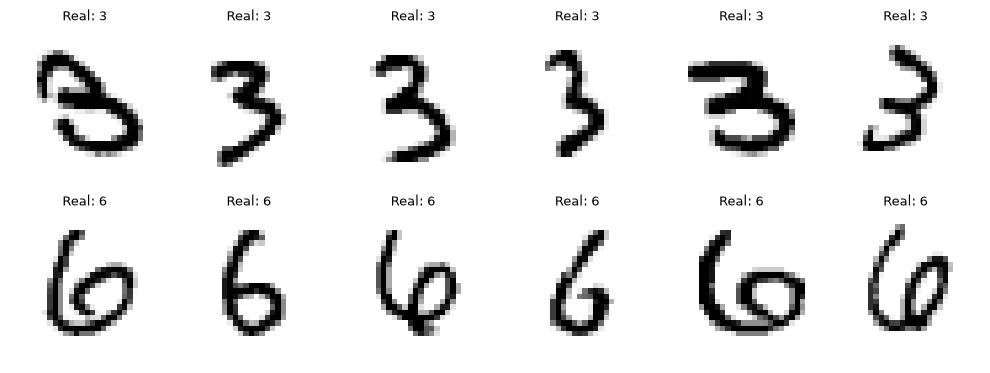

In [4]:
mostrar_digitos()

In [5]:
svm_rigido = SVC(kernel="linear", C=1e6, tol=1e-6).fit(X_treino, y_treino)
svm_suave = SVC(kernel="linear", C=0.01, tol=1e-6).fit(X_treino, y_treino)

base, _ = np.linalg.qr(np.column_stack([svm_rigido.coef_[0], svm_suave.coef_[0]]))
X_plot = X_treino @ base
x_min, y_min = X_plot.min(axis=0) - 0.5
x_max, y_max = X_plot.max(axis=0) + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

## Margem rígida

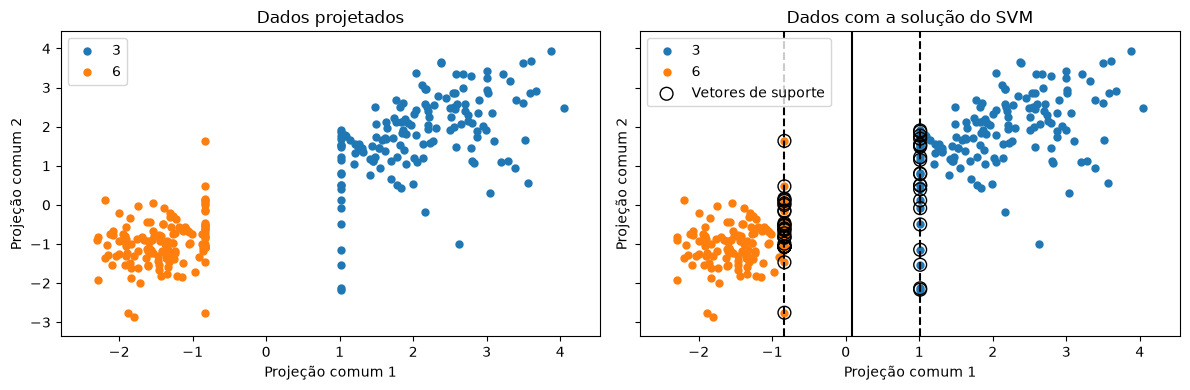

In [6]:
plotar_svm(svm_rigido)

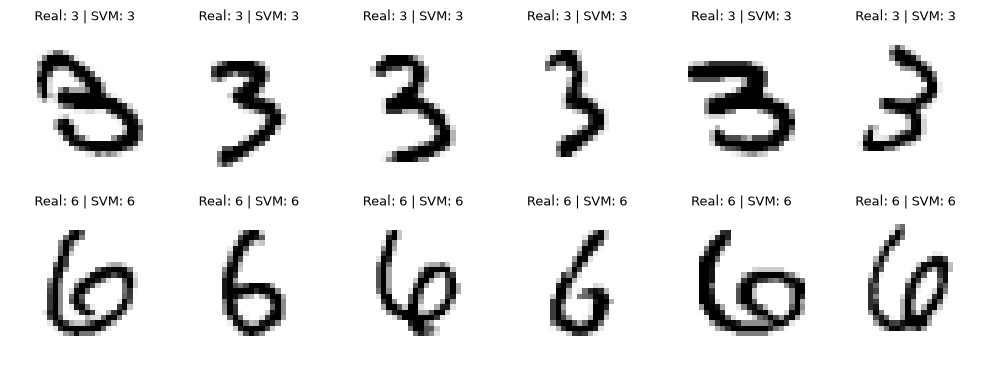

Previsto,3,6
Real,,
3,1002,8
6,9,949


In [7]:
mostrar_resultados(svm_rigido)

## Margem suave

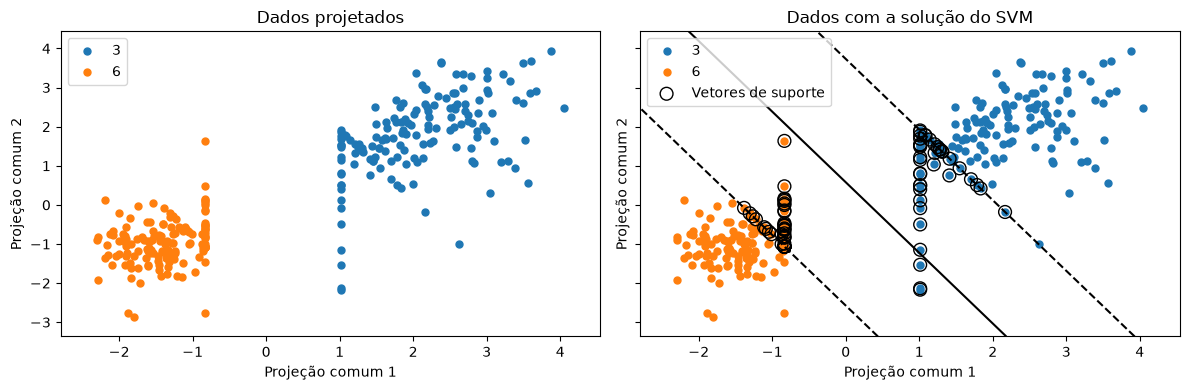

In [8]:
plotar_svm(svm_suave)

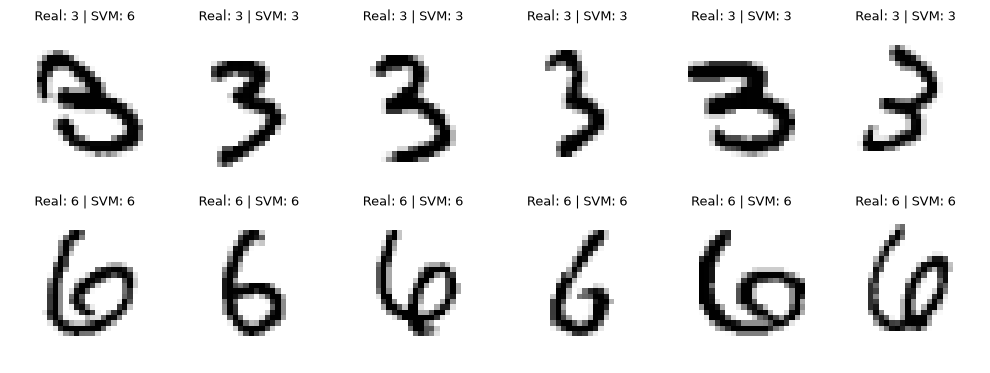

Previsto,3,6
Real,,
3,997,13
6,5,953


In [9]:
mostrar_resultados(svm_suave)